In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import os

import pandas as pd
from dotenv import load_dotenv

load_dotenv()

DATA_ROOT = Path(os.getenv("DATA_ROOT"))
NIH_DIR = DATA_ROOT / "NIH_Chest_X-Rays"

assert NIH_DIR.exists(), f"Dataset folder not found: {NIH_DIR}"
print(NIH_DIR)

C:\Users\profb\PROJECTS\datasets\NIH_Chest_X-Rays


In [3]:
from src.data import NIH_DISEASES, load_labels

df = load_labels(NIH_DIR)
print(df.shape)
df.head()

(112120, 25)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,width,height,spacing_x,...,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,...,0,0,0,0,0,0,0,0,0,0
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,...,0,1,0,0,0,0,0,0,0,0
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,...,1,0,0,0,0,0,0,0,0,0
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,...,0,0,0,0,0,0,0,0,0,0
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,...,0,0,0,1,0,0,0,0,0,0


## 1. Label Prevalence

In [4]:
counts = df[NIH_DISEASES].sum().sort_values(ascending=False)
prevalence = df[NIH_DISEASES].mean().sort_values(ascending=False)

pd.DataFrame({"count": counts, "prevalence": prevalence.round(4)})

,count,prevalence
Infiltration,19894,0.1774
Effusion,13317,0.1188
Atelectasis,11559,0.1031
Nodule,6331,0.0565
Mass,5782,0.0516
Pneumothorax,5302,0.0473
Consolidation,4667,0.0416
Pleural_Thickening,3385,0.0302
Cardiomegaly,2776,0.0248
Emphysema,2516,0.0224


## 2. No-Finding Rate and Labels Per Image

In [5]:
n_labels = df[NIH_DISEASES].sum(axis=1)

print(f"No finding: {(n_labels == 0).mean():.1%}")
n_labels.value_counts().sort_index()

No finding: 53.8%


0    60361
1    30963
2    14306
3     4856
4     1247
5      301
6       67
7       16
8        1
9        2
Name: count, dtype: int64

## 3. Co-Occurrence

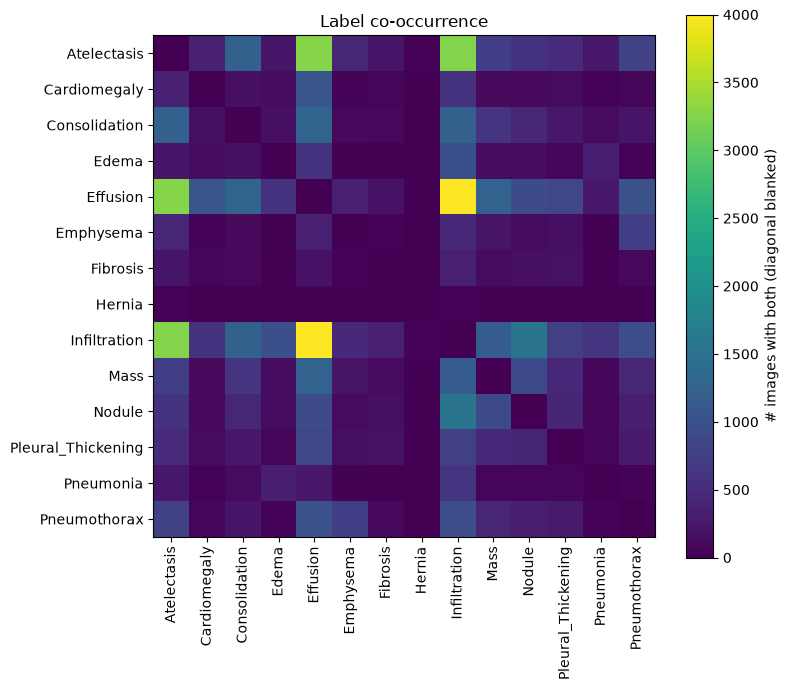

In [6]:
import matplotlib.pyplot as plt
import numpy as np

X = df[NIH_DISEASES]
co = (X.T @ X).to_numpy(copy=True)
np.fill_diagonal(co, 0)

plt.figure(figsize=(8, 7))
plt.imshow(co, cmap="viridis")
plt.xticks(range(len(NIH_DISEASES)), NIH_DISEASES, rotation=90)
plt.yticks(range(len(NIH_DISEASES)), NIH_DISEASES)
plt.colorbar(label="# images with both (diagonal blanked)")
plt.title("Label co-occurrence")
plt.tight_layout()
plt.show()

## 4. Patients

In [7]:
per_patient = df.groupby("Patient ID").size()

print(f"Images:   {len(df):,}")
print(f"Patients: {df['Patient ID'].nunique():,}")
per_patient.describe()

Images:   112,120
Patients: 30,805


count    30805.000000
mean         3.639669
std          7.266734
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
dtype: float64

In [8]:
per_patient.sort_values(ascending=False).head(10)

Patient ID
10007    184
13670    173
15530    158
12834    157
13993    143
1836     137
19124    130
20213    119
17138    117
11237    116
dtype: int64

## 5. View Position, Age, Gender

In [9]:
print(df["View Position"].value_counts(normalize=True))
print(df["Patient Gender"].value_counts(normalize=True))
df["Patient Age"].describe()

View Position
PA    0.600339
AP    0.399661
Name: proportion, dtype: float64
Patient Gender
M    0.56493
F    0.43507
Name: proportion, dtype: float64


count    112120.000000
mean         46.901463
std          16.839923
min           1.000000
25%          35.000000
50%          49.000000
75%          59.000000
max         414.000000
Name: Patient Age, dtype: float64

In [10]:
df[df["Patient Age"] > 100][["Image Index", "Patient ID", "Patient Age"]]

,Image Index,Patient ID,Patient Age
20852,00005567_000.png,5567,412
46965,00011973_002.png,11973,414
48284,00012238_010.png,12238,148
55742,00013950_000.png,13950,148
58650,00014520_026.png,14520,150
62929,00015558_000.png,15558,149
74884,00018366_044.png,18366,152
78795,00019346_000.png,19346,151
84810,00020900_002.png,20900,411
85404,00021047_002.png,21047,412


In [11]:
df.groupby("View Position")[NIH_DISEASES].mean().T.round(3)

View Position,AP,PA
Atelectasis,0.130,0.085
Cardiomegaly,0.027,0.023
Consolidation,0.070,0.023
Edema,0.045,0.004
Effusion,0.150,0.098
Emphysema,0.023,0.022
Fibrosis,0.006,0.021
Hernia,0.001,0.003
Infiltration,0.235,0.139
Mass,0.049,0.053


## Findings -> Decisions

- **Severe class imbalance.** Most common: Infiltration (17.7%). Rarest: Hernia (227 images, 0.2%, from 134 patients).
  → Use `pos_weight` in the loss; evaluate with per-class AUROC, not accuracy. Hernia metrics will have wide confidence intervals.
- **Multi-label.** 53.8% of images have no finding; ~18.8k images (16.8%) have 2+ labels (max 9).
  → One sigmoid per class with BCE loss, not softmax.
- **Strong co-occurrence.** Top pairs: Effusion+Infiltration (4,000), Atelectasis+Effusion (3,275), Atelectasis+Infiltration (3,264).
  → During error analysis, check whether predictions rely on correlated labels rather than the finding itself.
- **Repeated patients.** 112,120 images from 30,805 patients; median 1 image/patient, max 184.
  → Split by Patient ID to prevent leakage; bootstrap CIs by patient.
- **View-position confounding.** AP = 40% of images. Edema is ~11× more common in AP (4.5% vs 0.4%), Consolidation ~3×; Fibrosis is the reverse.
  → Risk of shortcut learning; report per-view performance later.
- **Age errors.** 16 images (16 patients) have ages 148–155 or 411–414.
  → Age is not a model input, so these rows are kept; noted as a data-quality issue.
- **Demographics.** 56.5% male, 43.5% female.
  → Optional later fairness check: per-sex AUROC.